### ${\color{#F6AA1C}{\rule{0.15em}{0.75em}}}$ ${\color{#6E1A81}{\small\textsf{CS 440 Assignment 2}}}$

**Bayesian Networks and Neural Networks**

**Deadline:** October 31st, 10:00 PM. **Total:** 100 points.

#### ${\color{#076838}{\small\textsf{How to use this notebook}}}$

1. Follow `README.md` to set up Python or Colab, then run the first code cell below.
   Read `HW2.pdf` for the team, late-submission and academic integrity rules.
2. Write your code and answers in the cells whose first line is `# GRADED: hw2` or
   `# GRADED: answers`. Do not change that first line, and do not rename the functions, classes or
   answer variables.
3. Only GRADED cells are used for grading. Put any extra imports, constants and helper
   functions in a cell with the same GRADED marker as the code that uses them (you can add cells).
   Use other cells for testing. Run cells in order as you complete each part; unfinished functions
   raise `NotImplementedError` until you replace the TODOs.
4. `math`, `torch` and `nn` are already imported in the `hw2` cells, and `math` in the `answers`
   cells.
5. A multiple-choice answer is a letter such as `"B"`. A numerical answer can be a Python expression
   such as `0.2 * 0.5`. Numbers within 0.1% of the exact value are accepted.
6. To test your work, save the notebook and run `check("p1")`, `check("p2")`, `check("p3")`, or
   `check()` for all problems. It reads the saved file locally, or the open notebook in Colab.
   It tests your code on example inputs and checks answer formats, not answer correctness.
   For Problem 3(c), it reports validation accuracy; your grade uses a separate test set.
7. Submit only `hw2.ipynb` on Gradescope and add all team members.

Keep the `hw2lib/` folder next to this notebook and do not change it. In Colab, follow the zip
upload instructions in `README.md`, then download your completed notebook
(File > Download > Download .ipynb) before submitting it.

In [4]:
# Run this cell first: pip install torch numpy matplotlib
import math

import torch
from torch import nn

torch.set_num_threads(1)  # Match the CPU setting used for grading.

from hw2lib.data import BURGLARY, load_fashion_mnist
from hw2lib.notebook import check
from hw2lib.viz import (compare_models, plot_activations, plot_data, plot_predictions,
                        plot_losses, plot_confusion_matrix)

---

#### ${\color{#6E1A81}{\small\textsf{Problem 1 (15 points)}}}$

Consider the following Bayesian network, where variables $A$ through $E$
are Boolean. The image has a typo: $P(D = true) = 0.2$ should read $P(A = true) = 0.2$.

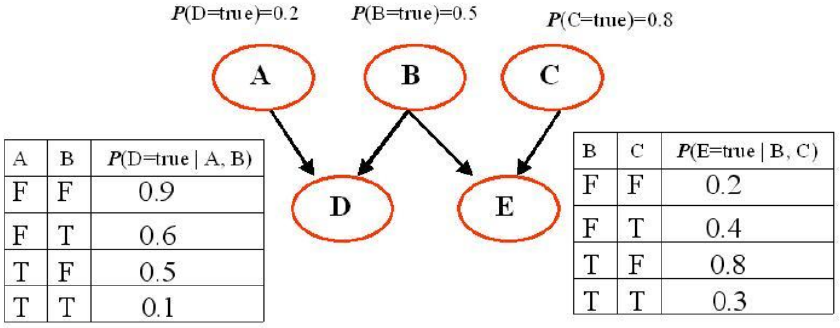

- ${\color{#076838}{\small\textsf{(a)}}}$ What is the probability that all five variables are true? (`P1A`, 5 points)
  [Hint: Use the network structure to write the joint probability as a product of the given
  probabilities.]
- ${\color{#076838}{\small\textsf{(b)}}}$ What is the probability that all five variables are false?
  (`P1B`, 5 points) [Hint: Use the same approach as in (a).]
- ${\color{#076838}{\small\textsf{(c)}}}$ What is the probability that $A$ is false given that the four other variables are all known to
  be true? (`P1C`, 5 points)

In [5]:
# GRADED: answers
P1A = 0.0024                  # a number
P1B = 0.0064                  # a number
P1C = 0.96                  # a number

In [6]:
check("p1")

Checking hw2.ipynb (saved at 15:48:45, 887 s ago). Save the notebook first if you have changed it.

P1 answers                         format check only
    P1A: format OK
    P1B: format OK
    P1C: format OK
Only the format of the answers is checked here.


---

#### ${\color{#6E1A81}{\small\textsf{Problem 2 (20 points)}}}$

Consider the "burglary" Bayesian network below.

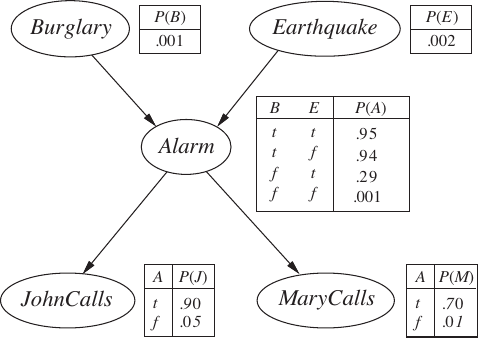

- ${\color{#076838}{\small\textsf{(a)}}}$ Calculate $P(Burglary \mid JohnCalls = true, MaryCalls = true)$ (`P2A`, 5 points). To do
  the calculation, write the function `enumeration_ask(query, evidence, network)`, which implements
  the enumeration algorithm from the book (10 points).
- ${\color{#076838}{\small\textsf{(b)}}}$ Suppose a Bayesian network has the form of a *chain*: a sequence of Boolean variables
  $X_1, \dots, X_n$ where $Parents(X_i) = \{X_{i-1}\}$ for $i = 2, \dots, n$. What is the complexity
  of computing $P(X_1 \mid X_n = true)$ using enumeration? (`P2B`, 5 points)

Choose the answer to (b) from:

- (A) $O(n)$
- (B) $O(n^2)$
- (C) $O(2^n)$
- (D) $O(n!)$

`BURGLARY` holds the network above. The docstring of `enumeration_ask` describes its format.

In [7]:
# GRADED: hw2
def enumeration_ask(query, evidence, network):
    """Return P(query = True | evidence), computed by enumeration.

    network is a list of (variable, parents, cpt) tuples in topological order
    (parents come before their children). All variables are Boolean. cpt maps a
    tuple of parent values, in the order of the parents list, to
    P(variable = True | parents). A variable without parents has the single key ().
    evidence is a dict {variable: True or False}; query is not in evidence.
    Sum the full joint distribution over the hidden variables, then normalize.
    """
    # TODO P2(a): write your code here and delete the raise below.
    raise NotImplementedError("TODO P2(a): enumeration_ask")

In [8]:
print(enumeration_ask("Burglary", {"JohnCalls": True, "MaryCalls": True}, BURGLARY))

NotImplementedError: TODO P2(a): enumeration_ask

In [ ]:
# GRADED: answers
P2A = None                  # a number
P2B = None                  # "A", "B", "C" or "D"

In [ ]:
check("p2")

---

#### ${\color{#6E1A81}{\small\textsf{Problem 3 (65 points)}}}$

Build a multilayer perceptron (MLP) with PyTorch to recognize clothing in
[Fashion-MNIST](https://www.kaggle.com/datasets/zalando-research/fashionmnist), a dataset from Zalando Research. Each example is a 28 by 28 grayscale
image with one of 10 labels, shown below. The input is the image flattened into 784 pixel values;
the model outputs 10 class scores. The starter includes 54,000 training images and 6,000 validation
images, along with functions to load the data and display images, predictions and training loss.

For help with PyTorch, read [Build the Neural Network](https://docs.pytorch.org/tutorials/beginner/basics/buildmodel_tutorial.html) and
[Optimizing Model Parameters](https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html). These tutorials also use Fashion-MNIST.
Additional reference: [Fashion-MNIST video tutorials](https://github.com/zalandoresearch/fashion-mnist#video-tutorial).
The notebook includes a small example to get you started.

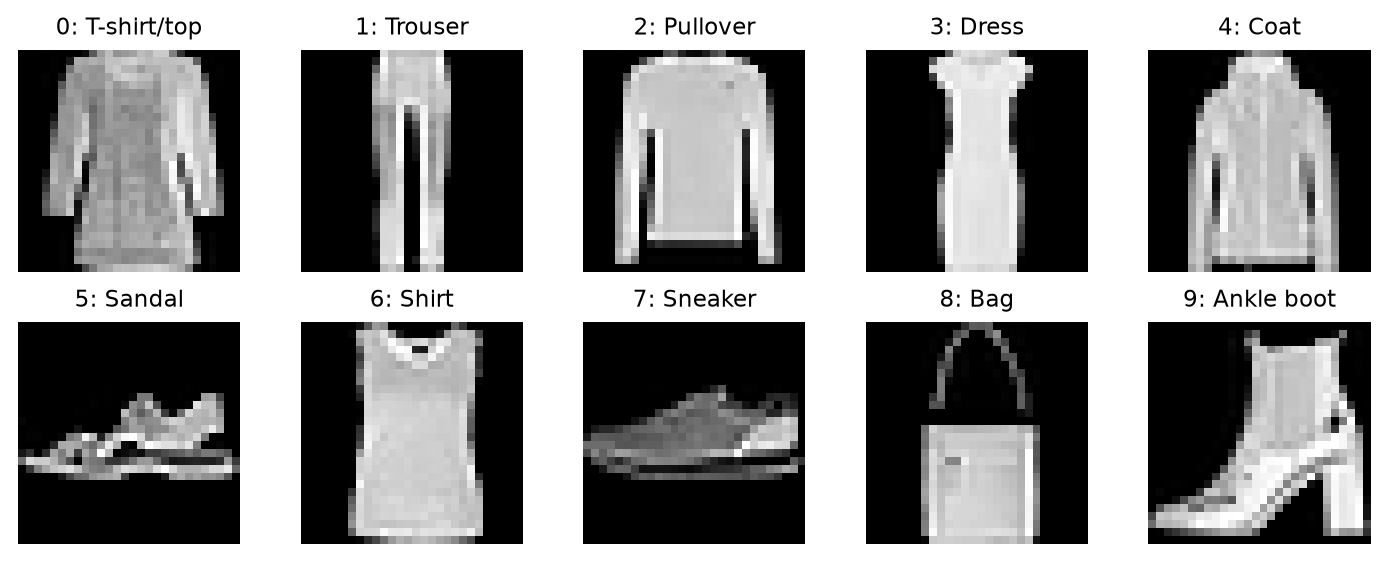

##### ${\color{#076838}{\small\textsf{Data and an example MLP}}}$

`load_fashion_mnist()` returns `X_train`, `y_train`, `X_val`, `y_val` and `class_names` in a dict.
Each row of `X` has 784 float32 pixel values in [0, 1] (the original values divided by 255).
Each `y` value is an int64 class index from 0 to 9. The data are included; no download is needed.
Use the provided splits so that your experiments and the tests use the same data.

torch.Size([54000, 784]) torch.Size([54000]) torch.Size([6000, 784])
{0: 'T-shirt/top', 1: 'Trouser', 2: 'Pullover', 3: 'Dress', 4: 'Coat', 5: 'Sandal', 6: 'Shirt', 7: 'Sneaker', 8: 'Bag', 9: 'Ankle boot'}


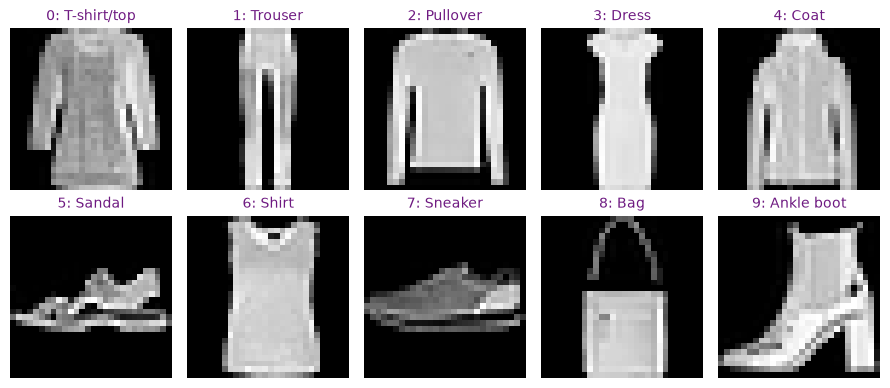

In [19]:
data = load_fashion_mnist()
print(data["X_train"].shape, data["y_train"].shape, data["X_val"].shape)
print(dict(enumerate(data["class_names"])))
plot_data(data);

This example (not graded) uses one hidden layer and trains on just 4,096 images to keep it
quick. `nn.CrossEntropyLoss` takes raw class scores and integer labels; do not apply softmax first.
Your functions below will train on the full training set.

last batch loss: 0.5420182347297668


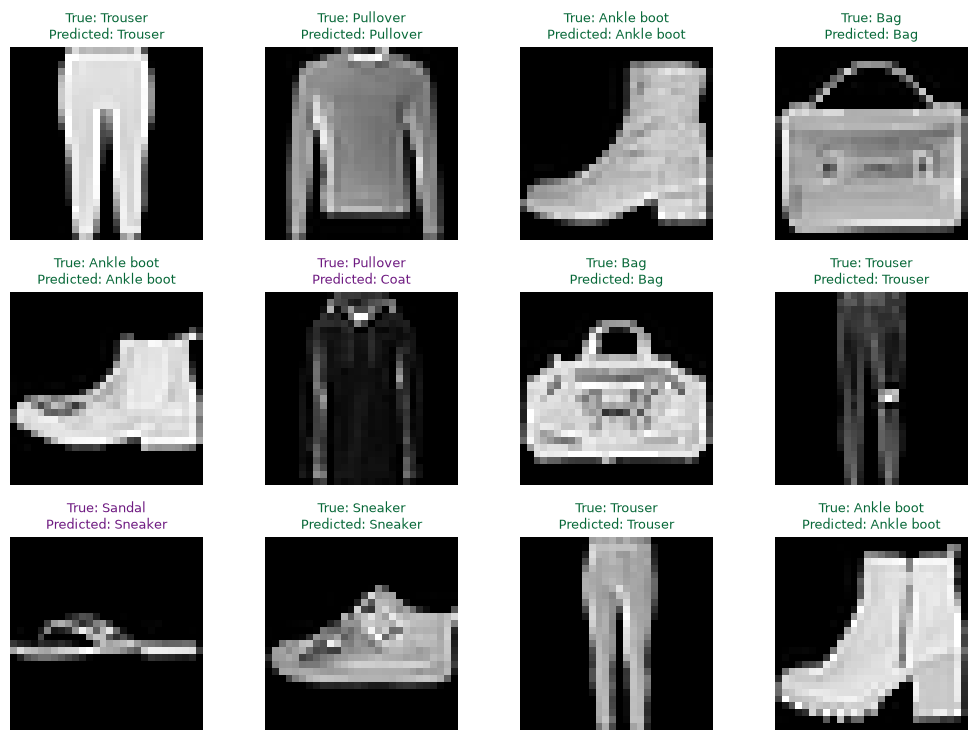

In [ ]:
class TinyMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(784, 64),  # 784 pixels -> 64 hidden units
            nn.ReLU(),
            nn.Linear(64, 10),   # one score per clothing class
        )

    def forward(self, x):
        return self.layers(x)


torch.manual_seed(0)
tiny = TinyMLP()
optimizer = torch.optim.Adam(tiny.parameters(), lr=0.001)
loss_fn = nn.CrossEntropyLoss()
X_demo, y_demo = data["X_train"][:4096], data["y_train"][:4096]
for epoch in range(5):
    order = torch.randperm(len(X_demo))
    for idx in order.split(128):
        optimizer.zero_grad()
        loss = loss_fn(tiny(X_demo[idx]), y_demo[idx])
        loss.backward()
        optimizer.step()
print("last batch loss:", loss.item())
plot_predictions(tiny, data);

- ${\color{#076838}{\small\textsf{(a)}}}$ Write a class `MLP(in_features, hidden_sizes, out_features, activation)` that subclasses
  `torch.nn.Module`. Build it from `nn.Linear` layers and activation modules: one `nn.Linear` layer
  for each hidden layer, each followed by an activation (`nn.ReLU`, `nn.Tanh`, `nn.Sigmoid`,
  `nn.LeakyReLU` or `nn.Identity`, chosen by `activation` = "relu", "tanh", "sigmoid", "leaky_relu"
  or "identity"), and a final `nn.Linear` output layer with no activation. The `forward` method
  returns the class scores. Support any input and output sizes, and an empty list of hidden layers.
  (15 points)

In [10]:
# GRADED: hw2
class MLP(nn.Module):
    """A multilayer perceptron built from nn.Linear layers and activation modules.

    MLP(in_features, hidden_sizes, out_features, activation) has one nn.Linear layer
    per hidden layer (hidden_sizes gives their sizes, in order; it can be empty) and
    one nn.Linear output layer with out_features outputs. Each hidden nn.Linear layer
    is followed by an activation module, chosen by name:
        "relu": nn.ReLU()   "tanh": nn.Tanh()   "sigmoid": nn.Sigmoid()
        "leaky_relu": nn.LeakyReLU()   "identity": nn.Identity()
    There is no activation after the output layer. Create the layers in __init__
    (for example in an nn.Sequential or an nn.ModuleList), in the order they are applied.
    forward(x) takes a tensor of shape (n, in_features) and returns the class scores
    (logits), a tensor of shape (n, out_features).
    """

    def __init__(self, in_features, hidden_sizes, out_features, activation="relu"):
        super().__init__()
        # TODO P3(a): write your code here and delete the raise below.
        
        # need to match each allowed activiation name to the Pytorch activation class 
        activationFunctions ={
            "relu": nn.ReLU, 
            "sigmoid": nn.Sigmoid, 
            "tanh": nn.Tanh, 
            "identity": nn.Identity,
            "leaky_relu": nn.LeakyReLU
        }

        #retrieve whichever activation call matches the choice
        activationClass = activationFunctions[activation]

        #empty list to store network's layers 
        layers=[]

        #need to keep track of how many input features the next layer is looking for 
        current_features = in_features

        #now we loop through the hidden layer sizes in the order given 
        for hidden_size in hidden_sizes: 

            #add a linear layer from the curent size to the hidden size we are on 
            layers.append(nn.Linear(current_features,hidden_size))
            #add the activation function selected after this hidden layer 
            layers.append(activationClass())
            #next layer gets the hidden layers outputs 
            current_features = hidden_size 

        #add final output layer with necessary number of outputs 
        layers.append(nn.Linear(current_features, out_features))

        #last combine all layers into a singular Pytorch module but keep in order 
        self.network=nn.Sequential(*layers)

    def forward(self, x):
        # TODO P3(a): write your code here and delete the raise below.
        
        #pass input though every later of self.network
        x = self.network(x)
        #return final scores for each input example
        return x

In [ ]:
print(MLP(784, [128, 64], 10, "relu"))

MLP(
  (network): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)


- ${\color{#076838}{\small\textsf{(b)}}}$ Write `train_model(model, X, y, epochs, lr, batch_size, seed)`, which trains the model with
  mini-batch Adam and cross-entropy loss and returns the average training loss of each epoch
  (10 points). Also write `predict(model, X)`, which returns the predicted class of each example
  (5 points). The docstrings in the notebook give the details.

In [11]:
# GRADED: hw2

def train_model(model, X, y, epochs, lr, batch_size=64, seed=0):
    """Train model on (X, y) and return a list with the average training loss of each epoch.

    X is a float tensor of shape (n, d) and y is an int64 tensor of n class indices.
      - Call model.train() and torch.manual_seed(seed), so that the shuffling is reproducible.
      - Use torch.optim.Adam(model.parameters(), lr=lr) and nn.CrossEntropyLoss().
      - In each epoch, shuffle the examples with torch.randperm(n), split them into
        mini-batches of batch_size examples (the last one may be smaller), and take
        one optimizer step per mini-batch.
      - The average loss of an epoch is the sum of loss.item() * (mini-batch size)
        over all mini-batches of the epoch, divided by n.
    """

    model.train()
    torch.manual_seed(seed)
    o = torch.optim.Adam(model.parameters(), lr=lr)
    nnccel = nn.CrossEntropyLoss()

    # n is the number of examples, one per epoch
    n = X.shape[0]
    epoch_losses = []
    for i in range(epochs):
        p = torch.randperm(n)
        tl = 0.0
        # Mini-batch loop
        for start in range(0, n, batch_size):
            idx = p[start:start + batch_size]
            xb, yb = X[idx], y[idx]
            o.zero_grad() # Clears gradients
            ls = nnccel(model(xb), yb)
            ls.backward() # New gradients
            o.step() # Update weights
            tl += ls.item() * xb.shape[0] # total loss
        epoch_losses.append(tl / n) # average loss per epoch
    return epoch_losses

In [12]:
# GRADED: hw2
def predict(model, X):
    """Return an int64 tensor of shape (n,) with the predicted class of each row of X
    (the index of the largest score). Call model.eval() and use torch.no_grad()."""

    #Evaluation mode
    model.eval()
    with torch.no_grad():
        scores = model(X)
    return scores.argmax(dim = 1) # return column of the largest score

validation accuracy: 0.8896666765213013


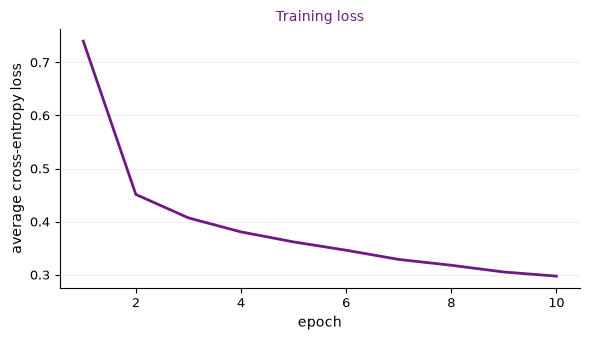

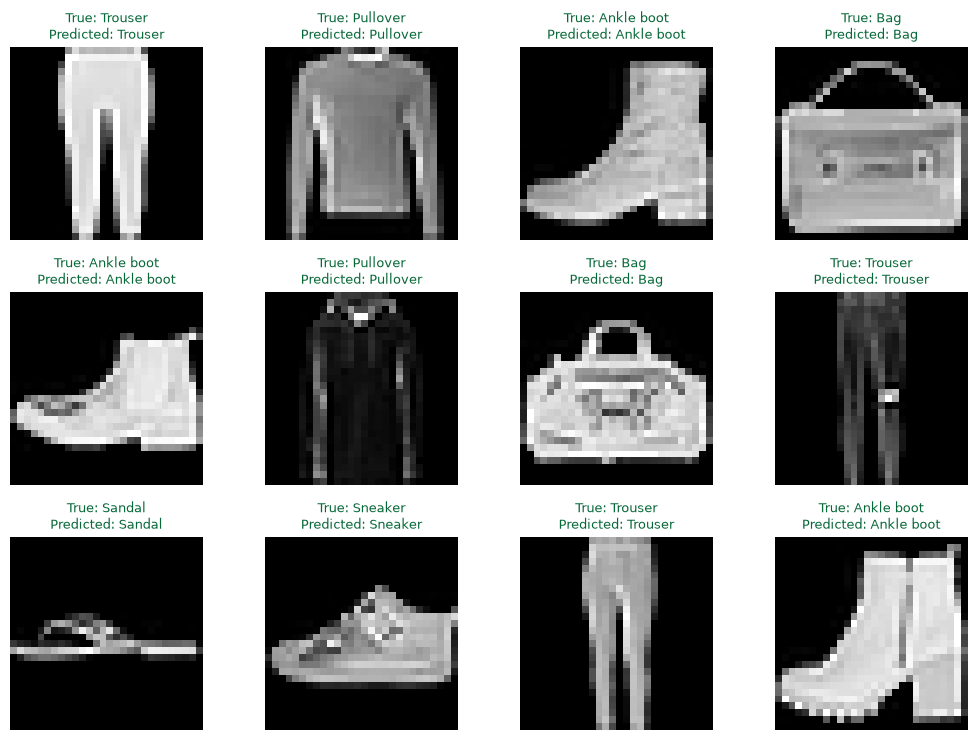

In [20]:
torch.manual_seed(0)
model = MLP(784, [128, 64], 10, "relu")
losses = train_model(model, data["X_train"], data["y_train"], epochs=10, lr=0.001, batch_size=256, seed=0)
val_acc = (predict(model, data["X_val"]) == data["y_val"]).float().mean().item()
print("validation accuracy:", val_acc)
plot_losses(losses)
plot_predictions(model, data);

- ${\color{#076838}{\small\textsf{(c)}}}$ Compare different hidden layers, layer sizes, activation functions and training settings
  using validation accuracy. Inspect the mistakes your models make. Then write
  `build_and_train(X_train, y_train, X_val, y_val)`, which builds your best model, trains it and
  returns it. Train on the training split only; use validation data to choose settings. Use only
  the supplied data and train from scratch. Convolutional layers and pretrained models are not
  allowed. Your model is evaluated on the 10,000 official test images. A test accuracy of 0.87 or
  more earns the full 20 points, 0.80 or less earns 0 points, and scores in between earn proportional
  credit. The model may have at most 2 million parameters, and `build_and_train` must finish within
  5 minutes on a CPU using one thread. (20 points)

These helpers are for your experiments (not graded):

- `plot_activations()` shows activation functions and their derivatives.
- `compare_models(MLP, train_model, configs, data)` compares validation accuracy and training loss.
- `plot_predictions(model, data, mistakes_only=True)` displays misclassified validation images.
- `plot_confusion_matrix(model, data)` shows which classes the model confuses.

The comparisons below use short runs. For part (c), try training promising models longer and
adjusting the learning rate. Each call to `check("p3")` or `check()` trains your part (c) model again.

In [ ]:
plot_activations();

In [ ]:
configs = [
    {"hidden_sizes": [], "activation": "relu"},
    {"hidden_sizes": [64, 64], "activation": "identity"},
    {"hidden_sizes": [64], "activation": "relu"},
    {"hidden_sizes": [128, 64], "activation": "relu"},
    {"hidden_sizes": [128, 64], "activation": "tanh"},
    {"hidden_sizes": [128, 64], "activation": "sigmoid"},
]
results = compare_models(MLP, train_model, configs, data, epochs=8, lr=0.001, batch_size=256)

In [ ]:
relu_model = results[3][1]
plot_confusion_matrix(relu_model, data);

In [21]:
# GRADED: hw2
def build_and_train(X_train, y_train, X_val, y_val):
    """Build, train, and return a neural network for Fashion-MNIST."""

   
    torch.manual_seed(42)

   
    model = MLP(784, [256, 128], 10, "relu")

   
    train_model(
        model,
        X_train,
        y_train,
        epochs=20,
        lr=0.001,
        batch_size=128,
        seed=42
    )

  
    return model

validation accuracy: 0.8996666669845581


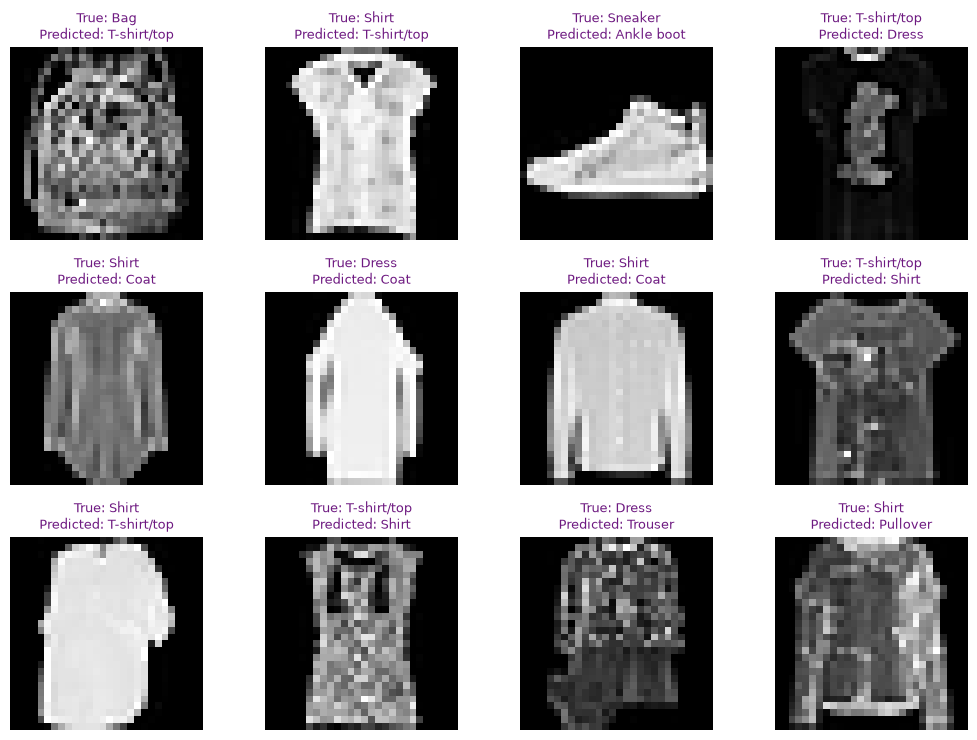

In [22]:
my_model = build_and_train(data["X_train"], data["y_train"], data["X_val"], data["y_val"])
val_acc = (predict(my_model, data["X_val"]) == data["y_val"]).float().mean().item()
print("validation accuracy:", val_acc)
plot_predictions(my_model, data, mistakes_only=True);

- ${\color{#076838}{\small\textsf{(d)}}}$ Answer the following questions (3 points each).
  - ${\color{#076838}{\small\textsf{(1)}}}$ With no hidden layers (`hidden_sizes = []`), each class score is (`P3D1`):
    (A) always between 0 and 1; (B) a weighted sum of the 784 pixel values plus a bias;
    (C) the index of the brightest pixel; (D) a product of the pixel values.
  - ${\color{#076838}{\small\textsf{(2)}}}$ A network with three hidden layers and only "identity" activations is equivalent to
    (`P3D2`): (A) a nearest-neighbor classifier; (B) a single linear layer with a bias;
    (C) a ReLU network; (D) a different kind of function for each choice of layer sizes.
  - ${\color{#076838}{\small\textsf{(3)}}}$ As a function of the pixel values, the class scores of a ReLU MLP are (`P3D3`):
    (A) always probabilities; (B) always constant; (C) smooth everywhere;
    (D) piecewise linear.
  - ${\color{#076838}{\small\textsf{(4)}}}$ A model has a training accuracy of 0.99 and a validation accuracy of 0.85. This is a sign of
    (`P3D4`): (A) overfitting; (B) underfitting; (C) a learning rate that is too small; (D) an error
    in the validation data.
  - ${\color{#076838}{\small\textsf{(5)}}}$ Deep networks with sigmoid activations often train more slowly than with ReLU activations.
    Why? (`P3D5`) (A) The sigmoid takes longer to compute. (B) The sigmoid can be negative.
    (C) The derivative of the sigmoid is at most 1/4, so the gradients can shrink from layer to
    layer. (D) The sigmoid makes the network linear.

In [24]:
# GRADED: answers
P3D1 = "B"                 # "A", "B", "C" or "D"
P3D2 = "B"
P3D3 = "D"
P3D4 = "A"
P3D5 = "C"

In [23]:
check("p3")

Checking hw2.ipynb (saved at 15:48:45, 1543 s ago). Save the notebook first if you have changed it.

P3(a) MLP                          15.00 / 15  (6/6 cases)
P3(b) train_model                  10.00 / 10  (4/4 cases)
P3(b) predict                       5.00 / 5  (3/3 cases)
P3(c) build_and_train              20.00 / 20
    validation accuracy 0.8997 -> 20 / 20 points (0 points at 0.8 or less, full credit at 0.87 or more)
    build_and_train took 10 s; the model has 235146 parameters
P3(d) answers                      format check only
    P3D1: still None  [0/3]
    P3D2: still None  [0/3]
    P3D3: still None  [0/3]
    P3D4: still None  [0/3]
    P3D5: still None  [0/3]

Total on the code examples: 50 / 50.
Only the format of the answers is checked here.


#### ${\color{#076838}{\small\textsf{Before you submit}}}$

Save the notebook, run the cell below, and upload `hw2.ipynb` to Gradescope.

In [ ]:
check()